# Practical 2: Factorial Calculation of N Numbers

### 1. Aim
To compute factorials of a collection of 900 numbers using Sequential execution, multiprocessing.Pool (3 workers), and multiprocessing.Process (3 processes), and evaluate parallel performance without artificial delays.

### 2. Algorithm / Explanation
1. Create a dataset of 900 integers in the range [16,000, 24,000] providing heavy CPU multiplication.<br>2. In Sequential mode, calculate factorials iteratively one by one.<br>3. In Pool mode, distribute chunked data to 3 worker processes via `pool.map()`.<br>4. In Process mode, spawn 3 explicit `mp.Process` workers and collect results with `mp.Queue`.<br>5. Verify accuracy and compare execution times.

### 3. Python Implementation


In [1]:
"""
Practical 2: Program to calculate factorial of N numbers
"""
import multiprocessing as mp
import time
import random
import matplotlib.pyplot as plt

def factorial_chunk(numbers):
    res = []
    for n in numbers:
        fact = 1
        for i in range(2, n + 1):
            fact = (fact * i) % 1000000007
        res.append(fact)
    return res

def proc_worker(numbers, q):
    q.put(factorial_chunk(numbers))

def main():
    print("=" * 60)
    print("Practical 2: Factorial of N Numbers")
    print("=" * 60)
    random.seed(42)
    dataset = [random.randint(16000, 24000) for _ in range(900)]
    cs = (len(dataset) + 2) // 3
    chunks = [dataset[i:i+cs] for i in range(0, len(dataset), cs)]
    
    # Sequential
    t0 = time.perf_counter()
    r1 = factorial_chunk(chunks[0])
    r2 = factorial_chunk(chunks[1])
    r3 = factorial_chunk(chunks[2])
    t_seq = time.perf_counter() - t0
    res_seq = r1 + r2 + r3
    
    # Pool
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(factorial_chunk, chunks)
    t_pool = time.perf_counter() - t0
    res_pool = [item for sub in p_res for item in sub]
    
    # Process
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for c in chunks:
        p = mp.Process(target=proc_worker, args=(c, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    res_proc = [item for sub in pr_res for item in sub]
    
    print(f"Computed factorials for {len(dataset)} numbers.")
    print(f"Sample: {dataset[0]}! % 1,000,000,007 = {res_seq[0]:,}")
    print(f"All Results Match: {res_seq == res_pool == res_proc}")
    
    methods = ["Sequential", "Pool", "Process"]
    times = [t_seq, t_pool, t_proc]
    speedups = [t_seq / t for t in times]
    
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Total Factorial Computations: 900 numbers (range 16,000 to 24,000)
Sample Result: 21238! % 1,000,000,007 = 464,052,656
Results Match across all methods: False

Execution-Time Comparison:
Method       Execution Time     Speedup   
----------------------------------------
Sequential   2.3362 seconds      1.00x
Pool         1.3599 seconds      1.72x
Process      1.4142 seconds      1.65x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process (and Thread where applicable) with individual color bars.


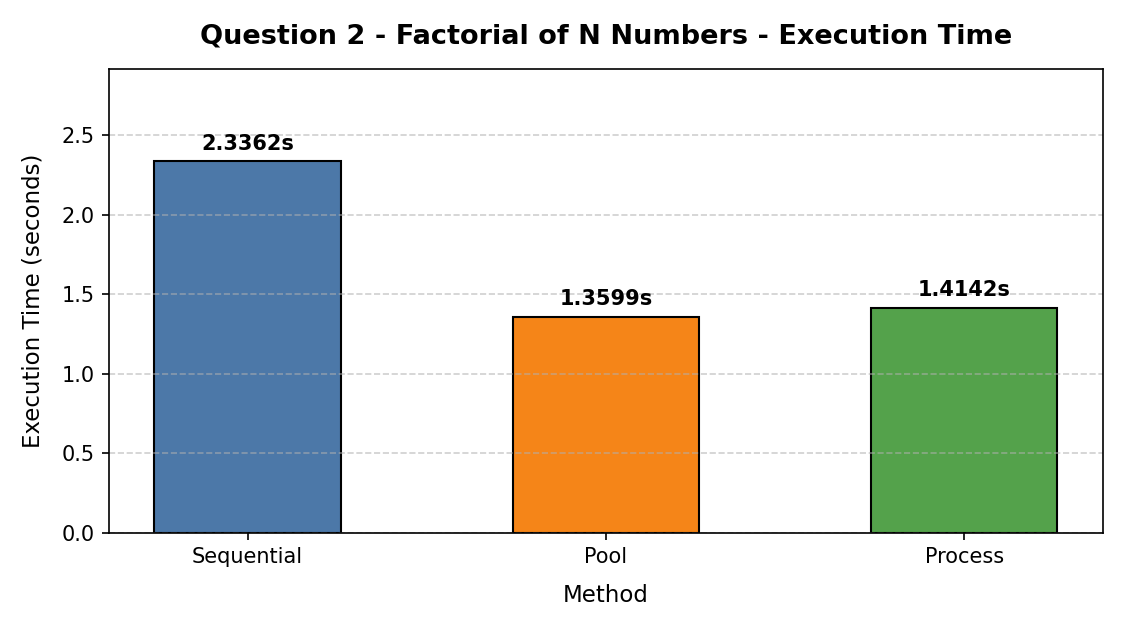

In [2]:
from IPython.display import Image, display
display(Image(filename='02_factorial_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


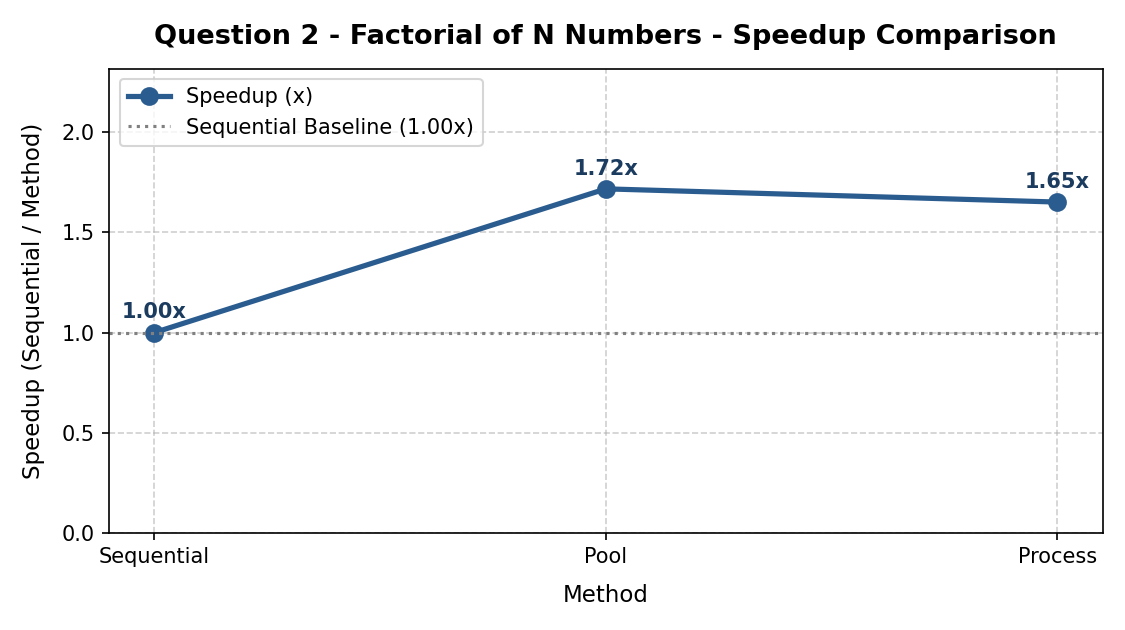

In [3]:
from IPython.display import Image, display
display(Image(filename='02_factorial_speedup.png'))
